# Deepfake Image Detection Using Deep Learning

## Project Overview

This project uses deep learning and transfer learning to classify facial images as **Real** or **Fake**.

The model uses **MobileNetV2**, a pretrained convolutional neural network, to extract image features and perform binary classification.

## Objectives

* Understand the real vs. fake image classification problem.
* Load and explore the dataset.
* Preprocess images for deep learning.
* Build and train a MobileNetV2-based classifier.
* Evaluate model performance using relevant metrics.
* Save the trained model for future predictions and web application integration.

## Technologies Used

* Python
* TensorFlow and Keras
* MobileNetV2
* NumPy and Matplotlib
* Scikit-learn
* Google Colab
* Streamlit

## Dataset

The project uses the Kaggle dataset **140k Real and Fake Faces**.

Dataset source: https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces

The dataset is divided into training, validation, and testing sets.

## Project Workflow

1. Dataset loading
2. Exploratory data analysis
3. Image preprocessing
4. Model development
5. Model training
6. Model evaluation
7. Model saving
8. Image prediction
9. Web application development

**Note:** Model predictions are experimental and should not be treated as definitive proof that an image is authentic or manipulated.


## 1. Import Libraries

In this section, we import the Python libraries required for data handling, image visualization, deep learning, and model evaluation.


In [1]:
# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Libraries imported successfully!


## 2. Dataset Loading

In this section, we download the Real and Fake Faces dataset using KaggleHub and define paths for the training, validation, and testing images.

The dataset is divided into three subsets:

* **Training set:** Used to train the model.
* **Validation set:** Used to monitor model performance during training.
* **Testing set:** Used for final evaluation on unseen images.


In [2]:
# Install KaggleHub
%pip -q install kagglehub

import kagglehub
import os

# Download dataset
path = kagglehub.dataset_download(
    "xhlulu/140k-real-and-fake-faces"
)

# Define dataset directories
data_dir = os.path.join(
    path, "real_vs_fake", "real-vs-fake"
)

train_dir = os.path.join(data_dir, "train")
valid_dir = os.path.join(data_dir, "valid")
test_dir = os.path.join(data_dir, "test")

# Verify paths
print("Training folder:", os.path.exists(train_dir))
print("Validation folder:", os.path.exists(valid_dir))
print("Testing folder:", os.path.exists(test_dir))

Using Colab cache for faster access to the '140k-real-and-fake-faces' dataset.
Training folder: True
Validation folder: True
Testing folder: True


## 3. Image Preprocessing

Deep learning models require images with consistent dimensions and labels. In this section, images are resized to 224 × 224 pixels and organized into training, validation, and testing datasets.

We use a batch size of 32 and assign labels as follows:

* **Fake = 0**
* **Real = 1**

The validation set helps monitor training, while the test set is reserved for final model evaluation.


In [3]:
# Image preprocessing configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Load training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["fake", "real"],
    shuffle=True,
    seed=SEED
)

# Load validation dataset
valid_ds = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["fake", "real"],
    shuffle=False
)

# Load test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["fake", "real"],
    shuffle=False
)

# Improve data pipeline performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
valid_ds = valid_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Image datasets loaded successfully!")

Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Image datasets loaded successfully!


In [4]:
print("Image datasets loaded successfully!")
print("Class labels: ['fake', 'real']")
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(valid_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Image datasets loaded successfully!
Class labels: ['fake', 'real']
Training batches: 3125
Validation batches: 625
Testing batches: 625


## 4. Model Development Using MobileNetV2

We use MobileNetV2, a pretrained convolutional neural network, as the feature extractor for binary image classification.

The pretrained base model is initially frozen to preserve its learned image features. A global average pooling layer, dropout layer, and sigmoid output layer are added to classify images as fake or real.

**Output classes:** Fake (0) and Real (1).


In [5]:
# Load the pretrained MobileNetV2 model
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build the classification model
inputs = layers.Input(shape=(224, 224, 3))

# Scale pixel values to the range expected by MobileNetV2
x = layers.Rescaling(1.0 / 127.5, offset=-1)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

# Sigmoid output for binary classification
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs)

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

# Display model architecture
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Model Checkpoint and Storage Setup

We save the trained model to Google Drive so that it can be reused for evaluation and deployment, even if the Colab runtime disconnects.

A model checkpoint will save the best-performing model based on validation loss during training.


In [6]:
# Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

# Create project directory in Google Drive
MODEL_DIR = "/content/drive/MyDrive/Deepfake-Image-Detection"
os.makedirs(MODEL_DIR, exist_ok=True)

# Define model save path
MODEL_PATH = os.path.join(MODEL_DIR, "deepfake_model.keras")

# Save the best model during training
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

print("Model directory:", MODEL_DIR)
print("Model will be saved to:", MODEL_PATH)
print("Checkpoint configured successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model directory: /content/drive/MyDrive/Deepfake-Image-Detection
Model will be saved to: /content/drive/MyDrive/Deepfake-Image-Detection/deepfake_model.keras
Checkpoint configured successfully!


## 6. Model Training

The model is trained using the training dataset and evaluated on the validation dataset after each epoch.

We use three initial epochs to establish a baseline. The best model is saved automatically according to validation loss, helping preserve the strongest checkpoint from this training run.


In [7]:
# Train the model
EPOCHS = 3

history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS,
    callbacks=[checkpoint]
)

Epoch 1/3
3124/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.6238 - loss: 0.6522 - precision: 0.6257 - recall: 0.6141
Epoch 1: val_loss improved from None to 0.52129, saving model to /content/drive/MyDrive/Deepfake-Image-Detection/deepfake_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Deepfake-Image-Detection/deepfake_model.keras
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 191s 54ms/step - accuracy: 0.6731 - loss: 0.6019 - precision: 0.6784 - recall: 0.6581 - val_accuracy: 0.7470 - val_loss: 0.5213 - val_precision: 0.7840 - val_recall: 0.6818
Epoch 2/3
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7316 - loss: 0.5403 - precision: 0.7410 - recall: 0.7105
Epoch 2: val_loss improved from 0.52129 to 0.49273, saving model to /content/drive/MyDrive/Deepfake-Image-Detection/deepfake_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Deepfake-Image-Detection/deepfake_model.keras
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 167s 53ms/step - accuracy: 0.7369 - 

## 7. Training Performance Visualization

We visualize training and validation accuracy and loss across epochs to understand the model's learning behavior and identify possible overfitting.

* **Accuracy:** Measures the proportion of correctly classified images.
* **Loss:** Measures the model's prediction error; lower values generally indicate better performance.


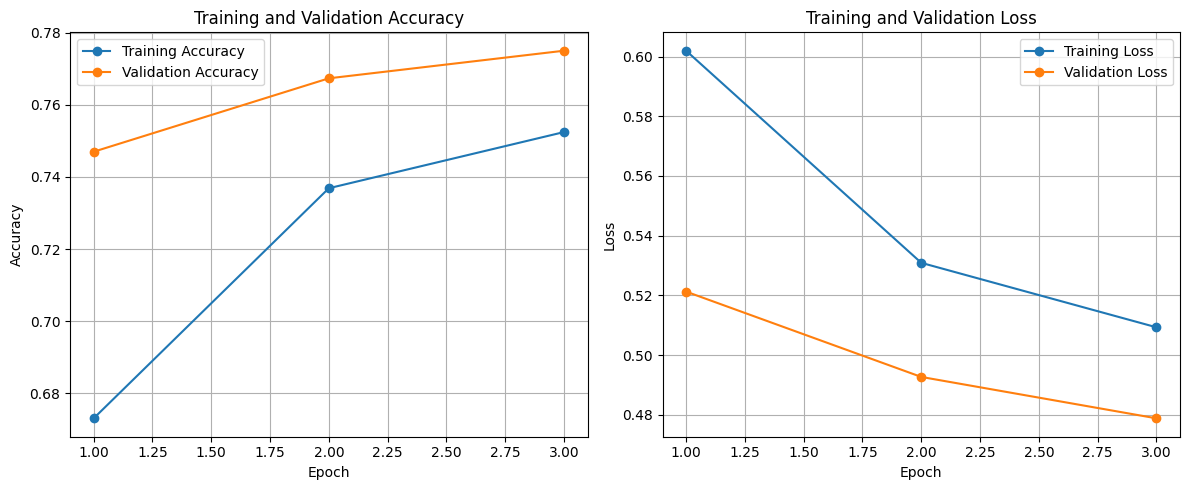

In [8]:
# Plot training and validation accuracy and loss
accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(accuracy) + 1)

plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, accuracy, marker="o", label="Training Accuracy")
plt.plot(epochs_range, val_accuracy, marker="o", label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, marker="o", label="Training Loss")
plt.plot(epochs_range, val_loss, marker="o", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 8. Model Evaluation

We evaluate the best saved model using the independent test dataset. We report test loss, accuracy, precision, and recall to assess classification performance on unseen images.

These metrics provide a broader evaluation than accuracy alone. Results depend on the dataset and should not be interpreted as proof that the model can reliably detect every deepfake in real-world images.


In [9]:
# Load the best saved checkpoint
best_model = tf.keras.models.load_model(MODEL_PATH)

# Evaluate on the test dataset
test_results = best_model.evaluate(
    test_ds,
    return_dict=True,
    verbose=1
)

print("\nTest Set Results")
print("-" * 30)

for metric, value in test_results.items():
    print(f"{metric.capitalize()}: {value:.4f}")

625/625 ━━━━━━━━━━━━━━━━━━━━ 32s 44ms/step - accuracy: 0.7756 - loss: 0.4795 - precision: 0.8011 - recall: 0.7333

Test Set Results
------------------------------
Accuracy: 0.7756
Loss: 0.4795
Precision: 0.8011
Recall: 0.7333


## 9. Classification Report and Confusion Matrix

We analyze predictions on the test dataset using a classification report and confusion matrix.

The classification report includes precision, recall, and F1-score for each class. The confusion matrix shows correct and incorrect predictions for Fake and Real images.


625/625 ━━━━━━━━━━━━━━━━━━━━ 33s 48ms/step
Classification Report

              precision    recall  f1-score   support

        Fake     0.7541    0.8179    0.7847     10000
        Real     0.8011    0.7333    0.7657     10000

    accuracy                         0.7756     20000
   macro avg     0.7776    0.7756    0.7752     20000
weighted avg     0.7776    0.7756    0.7752     20000



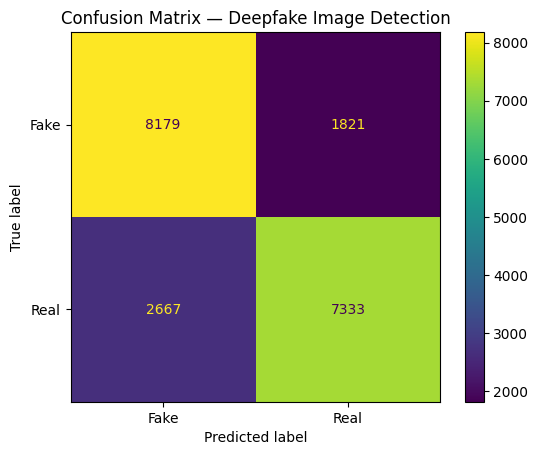

In [10]:
# Collect true labels from the test dataset
y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_ds
]).astype(int)

# Generate prediction probabilities
y_prob = best_model.predict(test_ds, verbose=1).ravel()

# Convert probabilities into class predictions
y_pred = (y_prob >= 0.5).astype(int)

# Print classification report
print("Classification Report\n")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Fake", "Real"],
        digits=4,
        zero_division=0
    )
)

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# Visualize confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake", "Real"]
)

display.plot(values_format="d")
plt.title("Confusion Matrix — Deepfake Image Detection")
plt.show()

## 10. Single Image Prediction

We create a reusable prediction function that accepts an image path, resizes the image to the model's expected input dimensions, and predicts whether the image is Real or Fake.

The model returns a probability for the Real class. Predictions are experimental and should not be treated as definitive proof that an image is authentic or manipulated.


In [11]:
from tensorflow.keras.utils import load_img, img_to_array
from IPython.display import display

def predict_deepfake(image_path):
    # Load and resize the image
    img = load_img(image_path, target_size=IMG_SIZE)

    # Convert image to a batch
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # Predict probability of the Real class
    real_probability = float(
        best_model.predict(img_array, verbose=0)[0][0]
    )

    prediction = "Real" if real_probability >= 0.5 else "Fake"
    score = real_probability if prediction == "Real" else 1 - real_probability

    # Display image and prediction
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"Prediction: {prediction}\n"
        f"Model score: {score:.2%}"
    )
    plt.show()

    print("Predicted class:", prediction)
    print(f"Real-class probability: {real_probability:.4f}")
    print("Note: This is an experimental model prediction, not a guarantee.")

print("Single-image prediction function is ready!")

Single-image prediction function is ready!


In [12]:
# Find one image from each test class
fake_images = tf.io.gfile.glob(os.path.join(test_dir, "fake", "*"))
real_images = tf.io.gfile.glob(os.path.join(test_dir, "real", "*"))

print("Fake image example:", fake_images[0])
print("Real image example:", real_images[0])

Fake image example: /kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test/fake/DAOH5G9O0Z.jpg
Real image example: /kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test/real/52876.jpg


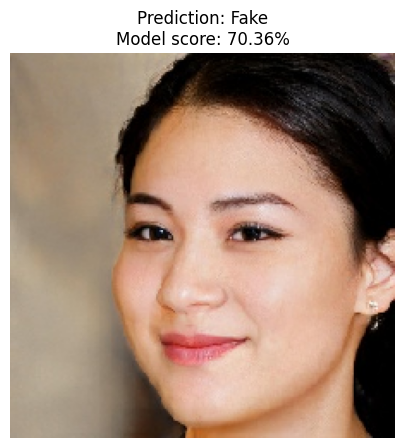

Predicted class: Fake
Real-class probability: 0.2964
Note: This is an experimental model prediction, not a guarantee.


In [13]:
predict_deepfake(fake_images[0])

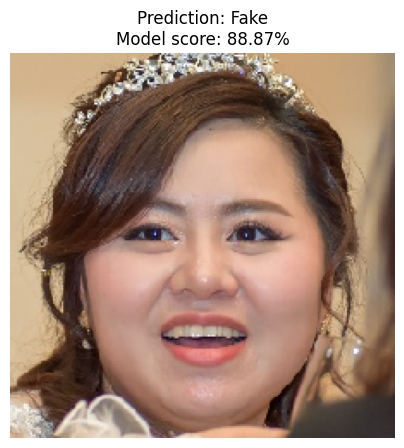

Predicted class: Fake
Real-class probability: 0.1113
Note: This is an experimental model prediction, not a guarantee.


In [14]:
predict_deepfake(real_images[0])